In [1]:
import sys
sys.path.insert(0, "../src")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from femuralabs.toolkit.arrays import window_to_uint8

In [3]:
rng = np.random.default_rng(0)

fake = np.concatenate([
    rng.normal(-1000, 20, 4000), #air
    rng.normal(40, 30, 3000), # soft-tissue
    rng.normal(600, 150, 800), # bone tail
])

fake.shape, fake.min(), fake.max()

((7800,), np.float64(-1077.9884346010867), np.float64(1010.7082931120568))

In [4]:
def save_histogram(values: np.ndarray, path: Path) -> None:
    """Plot an intensity histogram with labelled axis and save at 200 dpi."""
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.hist(values.ravel(), bins=60)
    ax.set_xlabel("intensity (HU)")
    ax.set_ylabel("number of voxels")
    ax.set_title("Synthetic intensity histogram")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)

In [5]:
Path("../reports").mkdir(exist_ok=True)
save_histogram(fake, Path("../reports/histogram.png"))

NameError: name 'fig' is not defined

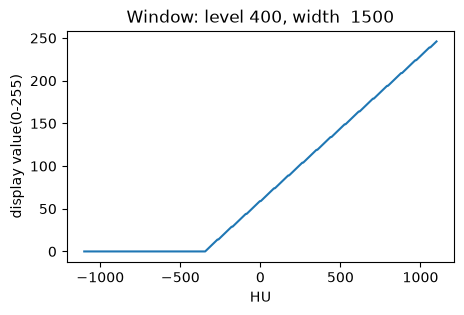

In [7]:
def save_window_curve(level: float, width: float, path: Path) -> None:
    """Plot display value against HU for one window."""
    hu = np.linspace(-1100, 1100, 400)
    fix, ax = plt.subplots(figsize=(5, 3))
    ax.plot(hu, window_to_uint8(hu, level, width))
    ax.set_xlabel("HU")
    ax.set_ylabel("display value(0-255)")
    ax.set_title(f"Window: level {level:g}, width {width: g}")
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.close(fig)

save_window_curve(400, 1500, Path("../reports/window_curve.png"))